# Part 2 - DistilBERT fine-tuning, LIAR test and final comparison

Run Part 1 first (in its own session). This notebook reads what Part 1 saved in the Google Drive folder `fake_news_classifier` (`isot_raw.csv`, `liar_clean.csv`, `part1_results.npz`) and saves the fine-tuned DistilBERT there too. No TensorFlow is loaded here. Runtime -> Change runtime type -> T4 GPU.

In [1]:
import os
import random
import gc
import psutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, roc_auc_score

In [2]:
# the results and weights are kept in google drive, so the next session can pick them up
from google.colab import drive
drive.mount('/content/drive')

save_dir = '/content/drive/MyDrive/fake_news_classifier'
os.makedirs(save_dir, exist_ok = True)
print(os.listdir(save_dir))

Mounted at /content/drive
['isot_raw.csv', 'lstm_model.keras', 'liar_clean.csv', 'part1_results.npz']


In [3]:
df = pd.read_csv(save_dir + '/isot_raw.csv')
df.shape

(39089, 2)

In [4]:
df['label'].value_counts()

,count
label,
0,21195
1,17894


# DistilBERT Fine-tuning

DistilBERT works best on the natural text (stop words, punctuation and word order all matter to it), so here I use `df['raw']` and not `clean_text`. Same train/test split as the other models so the scores can be compared.

In [5]:
import torch
import random
from torch.utils.data import DataLoader
from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding, get_linear_schedule_with_warmup

In [6]:
# needs a GPU runtime (Runtime -> Change runtime type -> T4 GPU), on cpu this will take hours
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
use_amp = device.type == 'cuda'
print('Device :', device)
print('RAM used : %.1f GB of %.1f GB' % (psutil.virtual_memory().used / 1e9, psutil.virtual_memory().total / 1e9))

Device : cuda
RAM used : 3.6 GB of 13.6 GB


In [7]:
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)

In [8]:
model_name = 'distilbert-base-uncased'
max_len = 256
batch_size = 32
epochs = 3
lr = 2e-5              # 2e-5 to 5e-5 is the usual range for fine-tuning
weight_decay = 0.01
warmup_ratio = 0.1
patience = 2

In [9]:
# True -> runs everything on a small sample just to check that the pipeline works, False -> full training
debug = False

Train / validation / test split

In [10]:
X_raw = df['raw']
y = df['label']
X_train_raw, X_test_bert, y_train_raw, y_test_bert = train_test_split(X_raw, y, test_size=0.2, stratify=y, random_state=42)

In [11]:
# 10% of the training data is kept aside for validation, test set is only used once at the end
X_tr, X_val, y_tr, y_val = train_test_split(X_train_raw, y_train_raw, test_size=0.1, stratify=y_train_raw, random_state=42)

In [12]:
if debug == True:
    X_tr, y_tr = X_tr.iloc[:2000], y_tr.iloc[:2000]
    X_val, y_val = X_val.iloc[:500], y_val.iloc[:500]
    X_test_bert, y_test_bert = X_test_bert.iloc[:500], y_test_bert.iloc[:500]

In [13]:
X_tr.shape, X_val.shape, X_test_bert.shape

((28143,), (3128,), (7818,))

In [14]:
y_tr.value_counts()

,count
label,
0,15260
1,12883


Tokenization

In [15]:
tokenizer = AutoTokenizer.from_pretrained(model_name)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

In [16]:
tokenizer.tokenize('The senate passed the bill on Friday.')

['the', 'senate', 'passed', 'the', 'bill', 'on', 'friday', '.']

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (988 > 512). Running this sequence through the model will result in indexing errors


[467.5  638.25 928.  ]


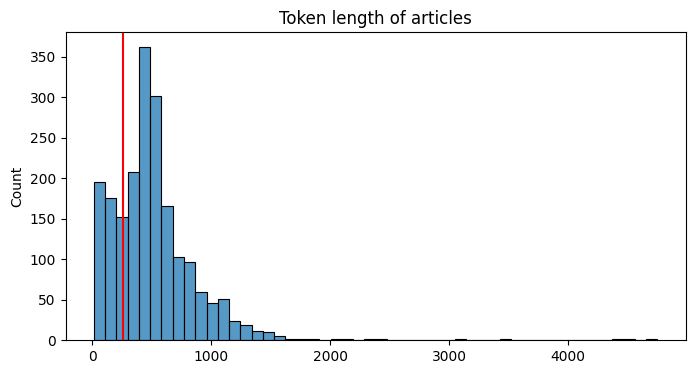

In [17]:
# how long are the articles in tokens, to check if max_len = 256 is enough
sample_lengths = [len(i) for i in tokenizer(X_tr.iloc[:2000].tolist())['input_ids']]
print(np.percentile(sample_lengths, [50, 75, 90]))

plt.figure(figsize=(8,4))
sns.histplot(sample_lengths, bins=50)
plt.axvline(max_len, color='red')
plt.title('Token length of articles')
plt.show()

In [18]:
train_enc = tokenizer(X_tr.tolist(), truncation=True, max_length=max_len)
val_enc = tokenizer(X_val.tolist(), truncation=True, max_length=max_len)
test_enc = tokenizer(X_test_bert.tolist(), truncation=True, max_length=max_len)

In [19]:
class NewsDataset(torch.utils.data.Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {
            'input_ids': self.encodings['input_ids'][idx],
            'attention_mask': self.encodings['attention_mask'][idx],
            'labels': int(self.labels[idx])
        }
        return item

In [20]:
# pads every batch only up to its longest article, not always to max_len
data_collator = DataCollatorWithPadding(tokenizer)

train_ds = NewsDataset(train_enc, y_tr.values)
val_ds = NewsDataset(val_enc, y_val.values)
test_ds = NewsDataset(test_enc, y_test_bert.values)

train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, collate_fn=data_collator)
val_loader = DataLoader(val_ds, batch_size=64, shuffle=False, collate_fn=data_collator)
test_loader = DataLoader(test_ds, batch_size=64, shuffle=False, collate_fn=data_collator)

In [21]:
batch = next(iter(train_loader))
batch['input_ids'].shape, batch['attention_mask'].shape, batch['labels'][:8]

(torch.Size([32, 256]),
 torch.Size([32, 256]),
 tensor([1, 0, 1, 1, 0, 1, 0, 1]))

Model

In [22]:
id2label = {0: 'Real', 1: 'Fake'}
label2id = {'Real': 0, 'Fake': 1}

# the warning about newly initialized classifier weights is expected, that layer is what we train from scratch
bert_model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=2, id2label=id2label, label2id=label2id)
bert_model.to(device)

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


DistilBertForSequenceClassification(
  (distilbert): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): DistilBertSelfAttention(
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_features=768, out_features=768, bias=True)
            (out_lin): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
          (ffn): FFN(
            (dropout): Dropout(p=0.1, inplace=False)


In [23]:
sum(p.numel() for p in bert_model.parameters())

66955010

In [24]:
# no weight decay on bias and layer norm weights
no_decay = ['bias', 'LayerNorm.weight', 'layer_norm.weight']
optimizer_params = [
    {'params': [p for n, p in bert_model.named_parameters() if not any(nd in n for nd in no_decay)], 'weight_decay': weight_decay},
    {'params': [p for n, p in bert_model.named_parameters() if any(nd in n for nd in no_decay)], 'weight_decay': 0.0}
]
optimizer = torch.optim.AdamW(optimizer_params, lr=lr)

In [25]:
# learning rate goes up for the first 10% of the steps and then decays linearly to 0
total_steps = len(train_loader) * epochs
warmup_steps = int(warmup_ratio * total_steps)
scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=warmup_steps, num_training_steps=total_steps)

# mixed precision (fp16) to make training faster on the gpu
scaler = torch.amp.GradScaler('cuda', enabled=use_amp)

print('Total steps :', total_steps, '| Warmup steps :', warmup_steps)

Total steps : 2640 | Warmup steps : 264


In [26]:
def train_one_epoch(model, loader):
    model.train()
    total_loss = 0
    n = 0
    for batch in tqdm(loader, leave=False):
        batch = {k: v.to(device) for k, v in batch.items()}
        optimizer.zero_grad()
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            outputs = model(**batch)
            loss = outputs.loss
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        total_loss += loss.item() * batch['labels'].size(0)
        n += batch['labels'].size(0)
    return total_loss / n

In [27]:
def evaluate(model, loader):
    model.eval()
    total_loss = 0
    all_preds = []
    all_probs = []
    all_labels = []
    with torch.no_grad():
        for batch in loader:
            batch = {k: v.to(device) for k, v in batch.items()}
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                outputs = model(**batch)
            total_loss += outputs.loss.item() * batch['labels'].size(0)
            probs = torch.softmax(outputs.logits.float(), dim=-1)[:, 1]
            all_probs.extend(probs.cpu().numpy())
            all_preds.extend(outputs.logits.argmax(dim=-1).cpu().numpy())
            all_labels.extend(batch['labels'].cpu().numpy())
    avg_loss = total_loss / len(all_labels)
    f1 = f1_score(all_labels, all_preds)
    return avg_loss, f1, np.array(all_preds), np.array(all_probs)

Training

In [28]:
print('RAM used : %.1f GB' % (psutil.virtual_memory().used / 1e9))
print('GPU memory used : %.1f GB' % (torch.cuda.memory_allocated() / 1e9))

RAM used : 6.5 GB
GPU memory used : 0.3 GB


In [29]:
best_f1 = -1
best_state = None
bad_epochs = 0
bert_history = {'train_loss': [], 'val_loss': [], 'val_f1': []}

for epoch in range(epochs):
    train_loss = train_one_epoch(bert_model, train_loader)
    val_loss, val_f1, _, _ = evaluate(bert_model, val_loader)

    bert_history['train_loss'].append(train_loss)
    bert_history['val_loss'].append(val_loss)
    bert_history['val_f1'].append(val_f1)
    print(f'Epoch {epoch + 1}/{epochs} | train loss {train_loss:.4f} | val loss {val_loss:.4f} | val f1 {val_f1:.5f}')

    # keep the weights of the best epoch (by validation f1), stop if it doesn't improve for 'patience' epochs
    if val_f1 > best_f1:
        best_f1 = val_f1
        best_state = {k: v.detach().cpu().clone() for k, v in bert_model.state_dict().items()}
        bad_epochs = 0
    else:
        bad_epochs += 1
        if bad_epochs >= patience:
            print('Early stopping')
            break

bert_model.load_state_dict(best_state)
print('Best validation f1 :', best_f1)

  0%|          | 0/880 [00:00<?, ?it/s]

Epoch 1/3 | train loss 0.0851 | val loss 0.0051 | val f1 0.99895


  0%|          | 0/880 [00:00<?, ?it/s]

Epoch 2/3 | train loss 0.0026 | val loss 0.0001 | val f1 1.00000


  0%|          | 0/880 [00:00<?, ?it/s]

Epoch 3/3 | train loss 0.0010 | val loss 0.0001 | val f1 1.00000
Best validation f1 : 1.0


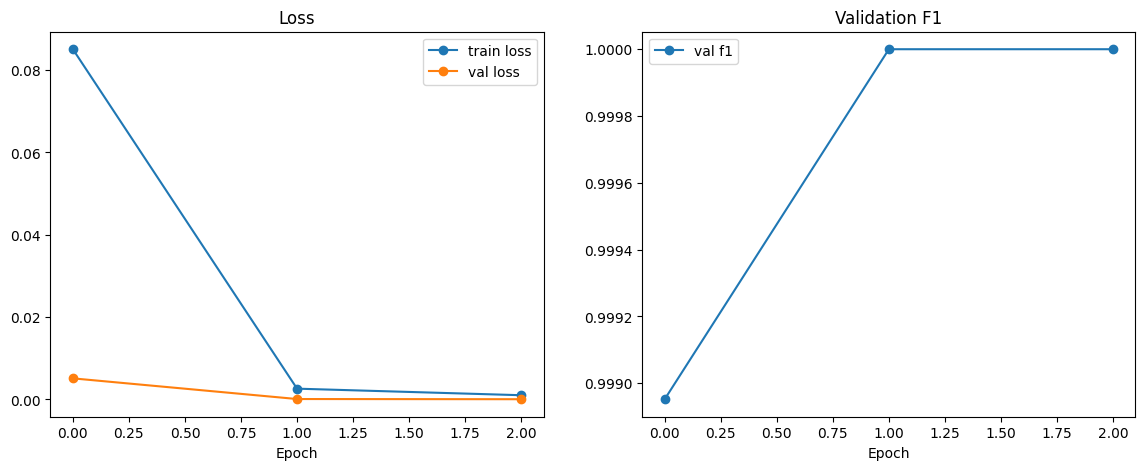

In [30]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14,5))
axes[0].plot(bert_history['train_loss'], marker='o', label='train loss')
axes[0].plot(bert_history['val_loss'], marker='o', label='val loss')
axes[0].set_title('Loss')
axes[0].set_xlabel('Epoch')
axes[0].legend()

axes[1].plot(bert_history['val_f1'], marker='o', label='val f1')
axes[1].set_title('Validation F1')
axes[1].set_xlabel('Epoch')
axes[1].legend()
plt.show()

Evaluation on the ISOT test set

Accuracy Score : 0.9994883601944231
              precision    recall  f1-score   support

           0    0.99953   0.99953   0.99953      4239
           1    0.99944   0.99944   0.99944      3579

    accuracy                        0.99949      7818
   macro avg    0.99948   0.99948   0.99948      7818
weighted avg    0.99949   0.99949   0.99949      7818

F1 Score : 0.9994411846884604


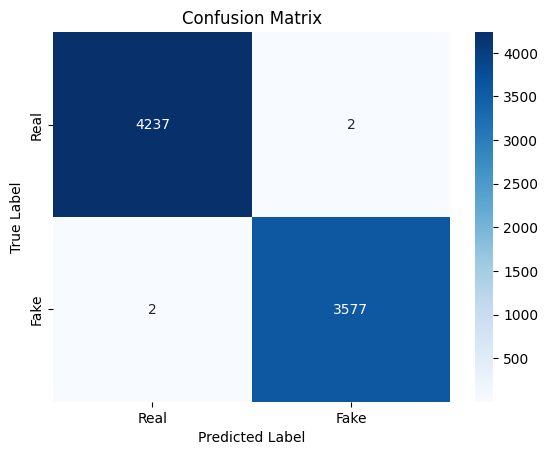

In [31]:
test_loss, test_f1, y_pred_bert, y_prob_bert = evaluate(bert_model, test_loader)
print('Accuracy Score :', accuracy_score(y_test_bert, y_pred_bert))
cm = confusion_matrix(y_test_bert, y_pred_bert)

target_names = ['Real', 'Fake']

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=target_names, yticklabels=target_names)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')

print(classification_report(y_test_bert, y_pred_bert, digits=5))
print('F1 Score :', f1_score(y_test_bert, y_pred_bert))

In [32]:
# articles the model got wrong
wrong = np.where(y_pred_bert != y_test_bert.values)[0]
print(len(wrong), 'wrong out of', len(y_test_bert))

4 wrong out of 7818


In [33]:
for i in wrong[:5]:
    print('Actual :', target_names[y_test_bert.values[i]], '| Predicted :', target_names[y_pred_bert[i]])
    print(X_test_bert.iloc[i][:300])
    print('-' * 80)

Actual : Fake | Predicted : Real
U.S. NEWS and WORLD REPORT Publishes List Of TOP 10 MOST POPULAR NATIONS Where Refugees Want To Live More than 21,000 people from all regions of the world participated in the Best Countries survey, in which they assessed how closely they associated 80 countries with specific characteristics. Four of
--------------------------------------------------------------------------------
Actual : Fake | Predicted : Real
The U.S. Establishment vs The Rest of World Thierry Meyssan Voltaire NetIt is a scandal without precedent.The White House Secretary General, Reince Priebus, was part of the plot designed to destabilise President Trump and prepare for his destitution. He was the source of daily leaks which trouble th
--------------------------------------------------------------------------------
Actual : Real | Predicted : Fake
Customers at a new charity shop in London walk away empty-handed and any money they spend goes to assist refugees in Europe and the Middl

In [34]:
bert_model.save_pretrained(save_dir + '/distilbert_fake_news')
tokenizer.save_pretrained(save_dir + '/distilbert_fake_news')

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('/content/drive/MyDrive/fake_news_classifier/distilbert_fake_news/tokenizer_config.json',
 '/content/drive/MyDrive/fake_news_classifier/distilbert_fake_news/tokenizer.json')

In [35]:
def predict_news(text):
    bert_model.eval()
    enc = tokenizer(text, truncation=True, max_length=max_len, return_tensors='pt').to(device)
    with torch.no_grad():
        logits = bert_model(**enc).logits
    probs = torch.softmax(logits.float(), dim=-1)[0]
    pred = int(probs.argmax())
    return id2label[pred], float(probs[pred])

In [36]:
print(predict_news(X_test_bert.iloc[0]))
print('Actual :', target_names[y_test_bert.values[0]])

('Real', 0.9999123811721802)
Actual : Real


# Testing on LIAR (second dataset)

LIAR is very different from ISOT. It has short claims said by politicians (checked by PolitiFact) and not full news articles. None of the models have seen it, so this shows how well they work outside ISOT. A big drop is expected.

In [37]:
liar = pd.read_csv(save_dir + '/liar_clean.csv')
y_liar = liar['fake']
liar.shape

(12836, 2)

DistilBERT on LIAR

In [38]:
liar_enc = tokenizer(liar['statement'].fillna('').tolist(), truncation=True, max_length=max_len)
liar_ds = NewsDataset(liar_enc, y_liar.values)
liar_loader = DataLoader(liar_ds, batch_size=64, shuffle=False, collate_fn=data_collator)

Accuracy Score : 0.5447958865690247
              precision    recall  f1-score   support

           0    0.59004   0.60527   0.59756      7167
           1    0.48414   0.46834   0.47611      5669

    accuracy                        0.54480     12836
   macro avg    0.53709   0.53681   0.53683     12836
weighted avg    0.54327   0.54480   0.54392     12836

F1 Score : 0.476105083833946
AUC : 0.5416431709367056


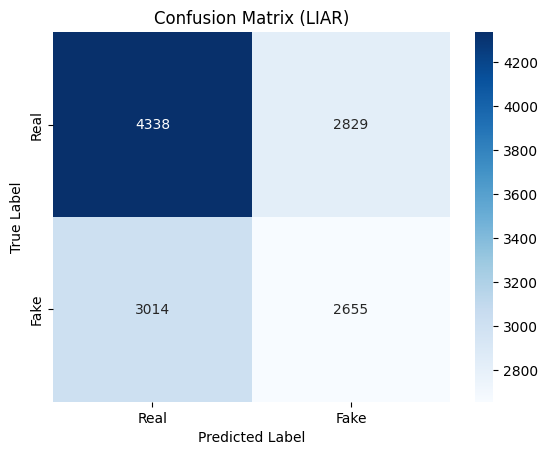

In [39]:
liar_loss, liar_f1, y_pred_liar_bert, y_prob_liar_bert = evaluate(bert_model, liar_loader)
print('Accuracy Score :', accuracy_score(y_liar, y_pred_liar_bert))
cm = confusion_matrix(y_liar, y_pred_liar_bert)

target_names = ['Real', 'Fake']

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=target_names, yticklabels=target_names)
plt.title('Confusion Matrix (LIAR)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')

print(classification_report(y_liar, y_pred_liar_bert, digits=5))
print('F1 Score :', f1_score(y_liar, y_pred_liar_bert))
print('AUC :', roc_auc_score(y_liar, y_prob_liar_bert))

# Final Comparison

In [40]:
p1 = np.load(save_dir + '/part1_results.npz')
y_test = pd.Series(p1['y_test'])
y_pred_tfidf, y_pred_w2v, y_pred_lstm = p1['y_pred_tfidf'], p1['y_pred_w2v'], p1['y_pred_lstm']
y_pred_liar_tfidf, y_pred_liar_w2v, y_pred_liar_lstm = p1['y_pred_liar_tfidf'], p1['y_pred_liar_w2v'], p1['y_pred_liar_lstm']
y_prob_liar_tfidf, y_prob_liar_w2v, y_prob_liar_lstm = p1['y_prob_liar_tfidf'], p1['y_prob_liar_w2v'], p1['y_prob_liar_lstm']

In [41]:
results = pd.DataFrame({
    'Model': ['TF-IDF + Random Forest', 'Word2Vec + Random Forest', 'LSTM', 'DistilBERT'],
    'ISOT F1': [f1_score(y_test, y_pred_tfidf), f1_score(y_test, y_pred_w2v), f1_score(y_test, y_pred_lstm), f1_score(y_test_bert, y_pred_bert)],
    'LIAR F1': [f1_score(y_liar, y_pred_liar_tfidf), f1_score(y_liar, y_pred_liar_w2v), f1_score(y_liar, y_pred_liar_lstm), f1_score(y_liar, y_pred_liar_bert)],
    'LIAR Accuracy': [accuracy_score(y_liar, y_pred_liar_tfidf), accuracy_score(y_liar, y_pred_liar_w2v), accuracy_score(y_liar, y_pred_liar_lstm), accuracy_score(y_liar, y_pred_liar_bert)],
    'LIAR AUC': [roc_auc_score(y_liar, y_prob_liar_tfidf), roc_auc_score(y_liar, y_prob_liar_w2v), roc_auc_score(y_liar, y_prob_liar_lstm), roc_auc_score(y_liar, y_prob_liar_bert)]
})
results.round(4)

,Model,ISOT F1,LIAR F1,LIAR Accuracy,LIAR AUC
0,TF-IDF + Random Forest,0.9775,0.6019,0.4536,0.5349
1,Word2Vec + Random Forest,0.9463,0.5284,0.5200,0.5413
2,LSTM,0.9816,0.5056,0.5167,0.5250
3,DistilBERT,0.9994,0.4761,0.5448,0.5416


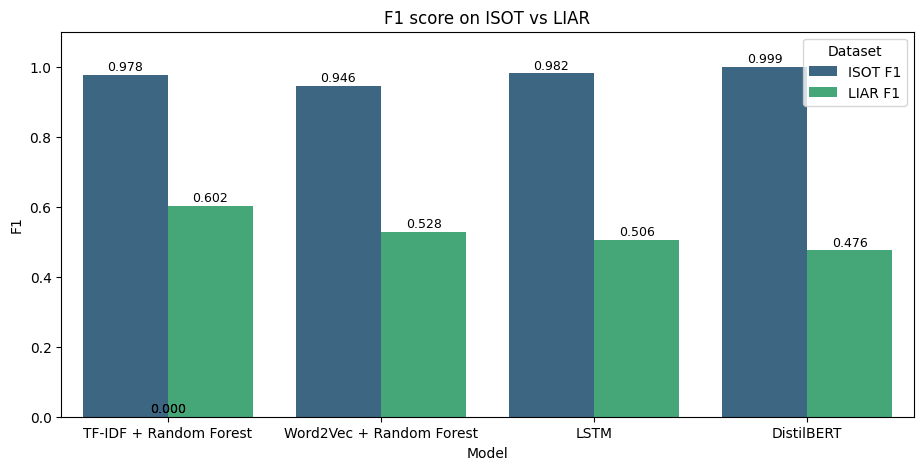

In [42]:
results_melted = results.melt(id_vars='Model', value_vars=['ISOT F1', 'LIAR F1'], var_name='Dataset', value_name='F1')

plt.figure(figsize=(11,5))
ax = sns.barplot(x='Model', y='F1', hue='Dataset', data=results_melted, palette='viridis')
plt.title('F1 score on ISOT vs LIAR')
plt.ylim(0, 1.1)
for p in ax.patches:
    ax.annotate(f'{p.get_height():.3f}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='baseline', fontsize=9, color='black', xytext=(0, 3),
                textcoords='offset points')
plt.show()

ISOT articles are long and come from only a few sources, LIAR claims are short one liners fact checked by PolitiFact. A model that learned the writing style of ISOT will not carry over, so the LIAR numbers (especially AUC, where 0.5 means no signal) are the more honest measure of how well the models detect fake news.